In [5]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [6]:
import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.copy('kaggle.json', '/root/.kaggle/kaggle.json')

os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [7]:
!pip install -q kaggle

In [8]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:30<00:00, 80.4MB/s]



In [9]:
import zipfile

with zipfile.ZipFile(
    '/content/chest-xray-pneumonia.zip', 'r'
) as zip_ref:
    zip_ref.extractall('/content/dataset')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [10]:
import os

print(os.listdir('/content/dataset/chest_xray'))

['__MACOSX', 'val', 'train', 'test', 'chest_xray']


In [13]:
dataset_path = '/content/dataset/chest_xray'

train_path = os.path.join(dataset_path, 'train')
val_path = os.path.join(dataset_path, 'val')
test_path = os.path.join(dataset_path, 'test')

print("Train folders:", os.listdir(train_path))
print("Validation folders:", os.listdir(val_path))
print("Test folders:", os.listdir(test_path))

Train folders: ['NORMAL', 'PNEUMONIA']
Validation folders: ['NORMAL', 'PNEUMONIA']
Test folders: ['NORMAL', 'PNEUMONIA']


In [12]:
import os

for root, dirs, files in os.walk('/content/dataset'):
    if 'train' in dirs and 'test' in dirs:
        print("Correct dataset path:", root)
        print("Folders:", dirs)

Correct dataset path: /content/dataset/chest_xray
Folders: ['__MACOSX', 'val', 'train', 'test', 'chest_xray']
Correct dataset path: /content/dataset/chest_xray/__MACOSX/chest_xray
Folders: ['val', 'train', 'test']
Correct dataset path: /content/dataset/chest_xray/chest_xray
Folders: ['val', 'train', 'test']


In [14]:
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = 224
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    label_mode='binary',
    seed=42
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    label_mode='binary',
    shuffle=False
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    label_mode='binary',
    shuffle=False
)

print("Classes:", train_data.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [15]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_data = train_data.map(
    lambda x, y: (normalization_layer(x), y)
)

val_data = val_data.map(
    lambda x, y: (normalization_layer(x), y)
)

test_data = test_data.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Preprocessing completed!")

Preprocessing completed!


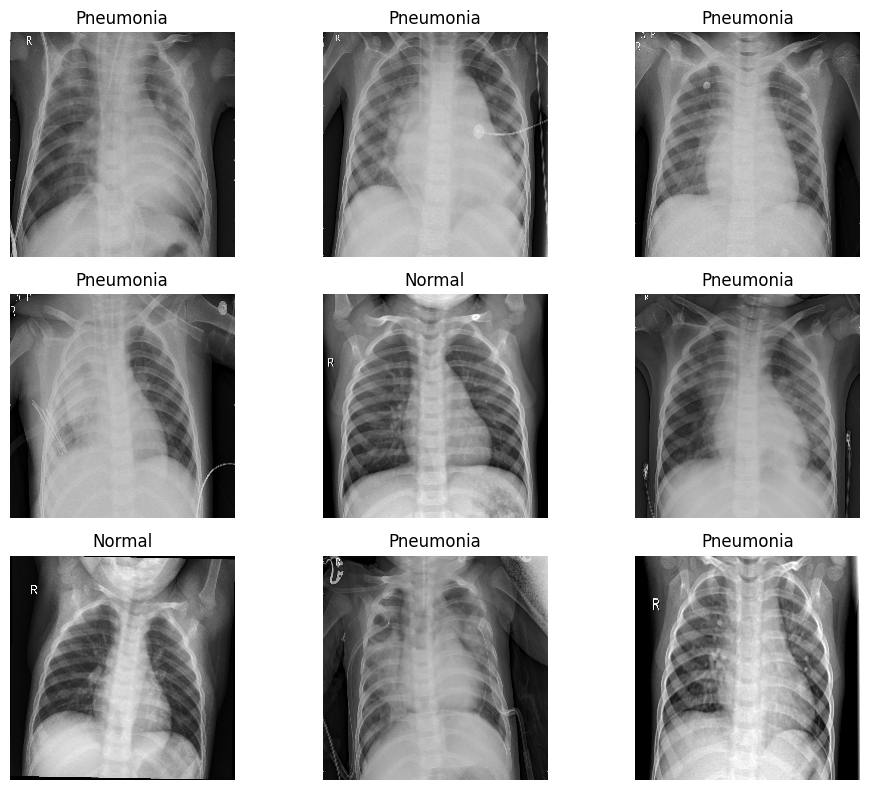

In [16]:
plt.figure(figsize=(10, 8))

for images, labels in train_data.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().squeeze(),
            cmap='gray'
        )

        label = int(labels[i].numpy().squeeze())
        plt.title('Pneumonia' if label == 1 else 'Normal')
        plt.axis('off')

plt.tight_layout()
plt.show()

In [17]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,513 (42.60 MB)

 Trainable params: 11,168,513 (42.60 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [20]:
import time
start_time = time.time()

history = cnn_model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

cnn_training_time = time.time() - start_time

print("Training time:", round(cnn_training_time / 60, 2), "minutes")

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 34s 147ms/step - accuracy: 0.8230 - loss: 0.3837 - val_accuracy: 0.8125 - val_loss: 0.3626
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 156ms/step - accuracy: 0.9333 - loss: 0.1810 - val_accuracy: 0.8750 - val_loss: 0.2972
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 148ms/step - accuracy: 0.9549 - loss: 0.1211 - val_accuracy: 0.9375 - val_loss: 0.2095
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 147ms/step - accuracy: 0.9664 - loss: 0.0958 - val_accuracy: 0.9375 - val_loss: 0.2461
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 146ms/step - accuracy: 0.9741 - loss: 0.0753 - val_accuracy: 0.9375 - val_loss: 0.1718
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 146ms/step - accuracy: 0.9747 - loss: 0.0685 - val_accuracy: 1.0000 - val_loss: 0.1084
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 23s 142ms/step - accuracy: 0.9774 - loss: 0.0602 - val_accuracy: 0.9375 - val_loss: 0.1623
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 145ms/step - accuracy: 0.9837 - loss: 0

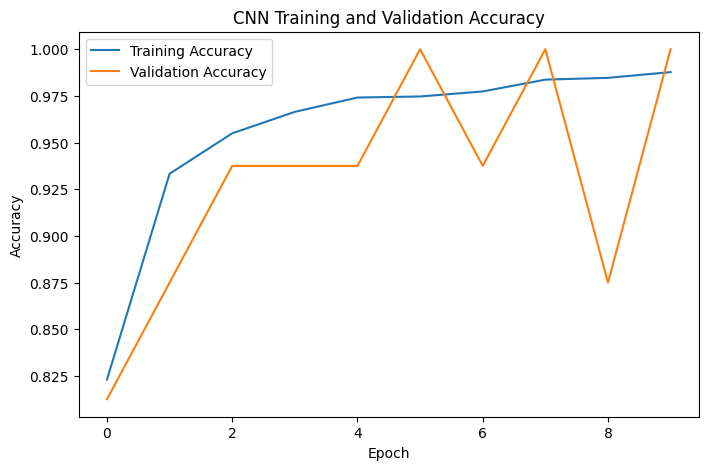

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Training and Validation Accuracy')
plt.legend()
plt.show()

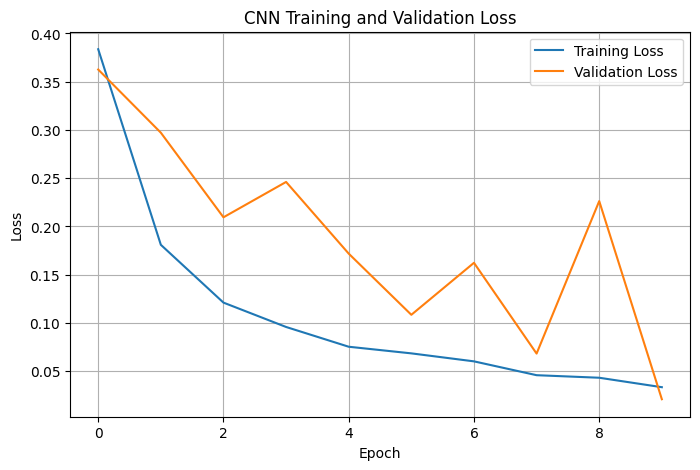

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

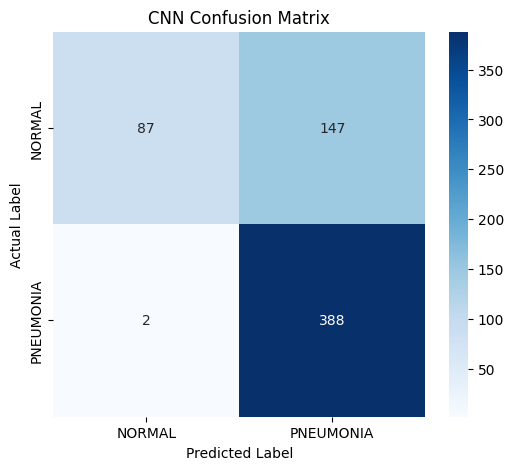

In [36]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true_cnn, y_pred_cnn)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['NORMAL', 'PNEUMONIA'],
    yticklabels=['NORMAL', 'PNEUMONIA']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('CNN Confusion Matrix')
plt.show()

In [23]:
test_loss, test_accuracy = cnn_model.evaluate(test_data)

print("CNN Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("CNN Test Loss:", round(test_loss, 4))

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7612 - loss: 1.7825
CNN Test Accuracy: 76.12 %
CNN Test Loss: 1.7825


In [26]:
cnn_results = {
    'Accuracy': test_accuracy,
    'Loss': test_loss,
    'Training Time (minutes)': cnn_training_time / 60
}

print(cnn_results)

{'Accuracy': 0.7612179517745972, 'Loss': 1.7824844121932983, 'Training Time (minutes)': 4.442229529221852}


In [32]:
from sklearn.metrics import classification_report
import numpy as np

y_true_cnn = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_data
]).astype(int)

y_prob_cnn = cnn_model.predict(test_data).ravel()
y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)

print(classification_report(
    y_true_cnn,
    y_pred_cnn,
    target_names=['NORMAL', 'PNEUMONIA'],
    zero_division=0
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step
              precision    recall  f1-score   support

      NORMAL       0.98      0.37      0.54       234
   PNEUMONIA       0.73      0.99      0.84       390

    accuracy                           0.76       624
   macro avg       0.85      0.68      0.69       624
weighted avg       0.82      0.76      0.73       624



In [35]:
cnn_model.save('/content/cnn_pneumonia_model.keras')

print("CNN model saved successfully!")

CNN model saved successfully!


In [37]:
import tensorflow as tf
import matplotlib.pyplot as plt
import time

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [38]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_rgb = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='binary',
    seed=42
)

val_rgb = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='binary',
    shuffle=False
)

test_rgb = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='binary',
    shuffle=False
)

print("RGB images loaded successfully!")
print("Classes:", train_rgb.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
RGB images loaded successfully!
Classes: ['NORMAL', 'PNEUMONIA']


In [39]:
train_rgb = train_rgb.map(
    lambda x, y: (preprocess_input(x), y)
)

val_rgb = val_rgb.map(
    lambda x, y: (preprocess_input(x), y)
)

test_rgb = test_rgb.map(
    lambda x, y: (preprocess_input(x), y)
)

print("Preprocessing completed!")

Preprocessing completed!


In [40]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("Pretrained MobileNetV2 loaded!")

Pretrained MobileNetV2 loaded!


In [41]:
transfer_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

transfer_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [42]:
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [43]:
start_time = time.time()

transfer_history = transfer_model.fit(
    train_rgb,
    validation_data=val_rgb,
    epochs=10
)

transfer_training_time = time.time() - start_time

print(
    "Training time:",
    round(transfer_training_time / 60, 2),
    "minutes"
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 43s 198ms/step - accuracy: 0.7665 - loss: 0.4848 - val_accuracy: 0.5000 - val_loss: 0.7317
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step - accuracy: 0.8484 - loss: 0.3514 - val_accuracy: 0.5625 - val_loss: 0.5936
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 189ms/step - accuracy: 0.8907 - loss: 0.2826 - val_accuracy: 0.6875 - val_loss: 0.5072
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 185ms/step - accuracy: 0.9118 - loss: 0.2466 - val_accuracy: 0.7500 - val_loss: 0.4602
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 190ms/step - accuracy: 0.9241 - loss: 0.2172 - val_accuracy: 0.7500 - val_loss: 0.4231
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 185ms/step - accuracy: 0.9348 - loss: 0.1965 - val_accuracy: 0.7500 - val_loss: 0.4091
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 194ms/step - accuracy: 0.9342 - loss: 0.1876 - val_accuracy: 0.7500 - val_loss: 0.3756
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 193ms/step - accuracy: 0.9429 - loss: 0

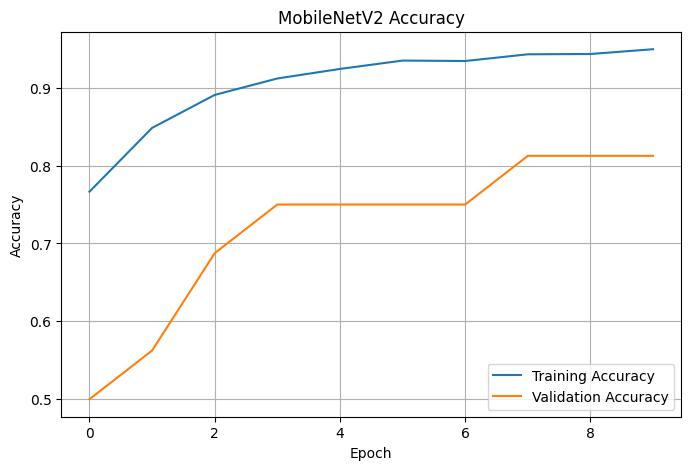

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    transfer_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    transfer_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

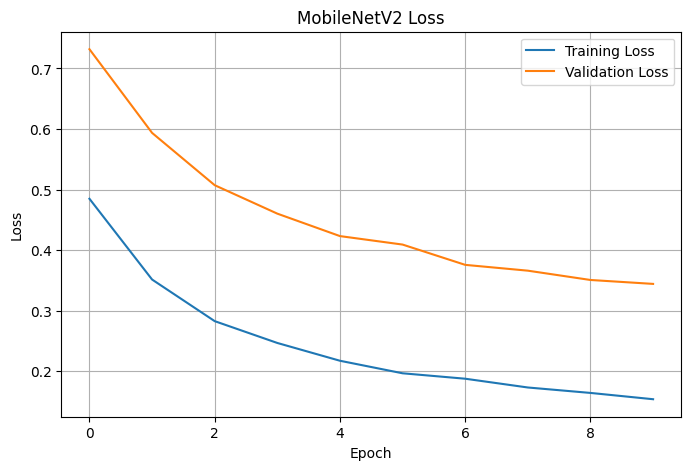

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    transfer_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    transfer_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('MobileNetV2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [46]:
transfer_loss, transfer_accuracy = transfer_model.evaluate(
    test_rgb
)

print(
    "MobileNetV2 Test Accuracy:",
    round(transfer_accuracy * 100, 2),
    "%"
)

print(
    "MobileNetV2 Test Loss:",
    round(transfer_loss, 4)
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.8013 - loss: 0.4036
MobileNetV2 Test Accuracy: 80.13 %
MobileNetV2 Test Loss: 0.4036


In [47]:
transfer_model.save(
    '/content/mobilenetv2_pneumonia_model.keras'
)

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


In [48]:
import numpy as np
from sklearn.metrics import classification_report

y_true_tl = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_rgb
]).astype(int)

y_prob_tl = transfer_model.predict(test_rgb).ravel()

y_pred_tl = (y_prob_tl >= 0.5).astype(int)

print(classification_report(
    y_true_tl,
    y_pred_tl,
    target_names=['NORMAL', 'PNEUMONIA'],
    zero_division=0
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 284ms/step
              precision    recall  f1-score   support

      NORMAL       0.97      0.48      0.65       234
   PNEUMONIA       0.76      0.99      0.86       390

    accuracy                           0.80       624
   macro avg       0.87      0.74      0.75       624
weighted avg       0.84      0.80      0.78       624



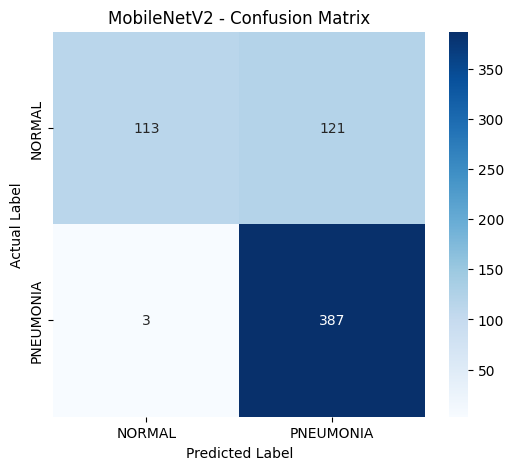

In [49]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_tl = confusion_matrix(y_true_tl, y_pred_tl)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tl,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['NORMAL', 'PNEUMONIA'],
    yticklabels=['NORMAL', 'PNEUMONIA']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('MobileNetV2 - Confusion Matrix')

plt.show()

In [50]:
transfer_results = {
    'Accuracy': transfer_accuracy,
    'Loss': transfer_loss,
    'Training Time (minutes)': transfer_training_time / 60
}

print(transfer_results)

{'Accuracy': 0.8012820482254028, 'Loss': 0.403554230928421, 'Training Time (minutes)': 5.520852263768514}


In [51]:
transfer_model.save(
    '/content/mobilenetv2_pneumonia_model.keras'
)

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


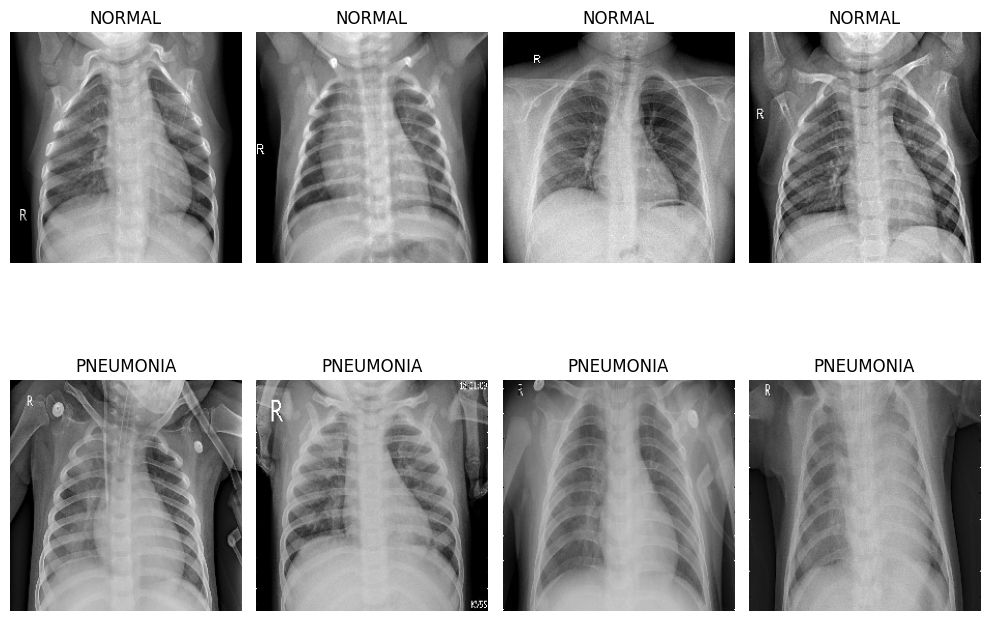

In [52]:
import matplotlib.pyplot as plt
import os
from tensorflow.keras.utils import load_img

normal_path = dataset_path + "/train/NORMAL"
pneumonia_path = dataset_path + "/train/PNEUMONIA"

normal_images = os.listdir(normal_path)
pneumonia_images = os.listdir(pneumonia_path)

plt.figure(figsize=(10, 8))

# 4 NORMAL images
for i in range(4):
    img = load_img(
        os.path.join(normal_path, normal_images[i]),
        target_size=(224, 224)
    )

    plt.subplot(2, 4, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title("NORMAL")
    plt.axis("off")

# 4 PNEUMONIA images
for i in range(4):
    img = load_img(
        os.path.join(pneumonia_path, pneumonia_images[i]),
        target_size=(224, 224)
    )

    plt.subplot(2, 4, i + 5)
    plt.imshow(img, cmap="gray")
    plt.title("PNEUMONIA")
    plt.axis("off")

plt.tight_layout()
plt.show()